## Week 10
Megan Yoos November 2nd, 2026

In [1]:
# first we need to import our visualization librarier and any other related components!

import json                                  # to read the GeoJSON shape files
import re                                    # regular expressions, from Part 9, to pick out the words

import matplotlib.pyplot as plt              # to display the word clouds
import pandas as pd                          # tables of data
import plotly.express as px                  # the quick way to make interactive charts and maps ("px")
import pydeck as pdk                         # 3D maps
from IPython.display import HTML, IFrame     # to show web pages and HTML inside the notebook
from wordcloud import STOPWORDS, WordCloud   # STOPWORDS is a set of common words to leave out



## Visualizing Poll Data
Ive included two files (house_average_recent.csv and senate_average_recent.csv) which contain average polls for senate and house races 

In [2]:


# read the two CSV files made by the prep notebook into tables (DataFrames)
house = pd.read_csv("house_average_recent.csv")
senate = pd.read_csv("senate_average_recent.csv")

# len() of a table is its number of rows: one row per district, and one row per state
print(len(house), "House districts,", len(senate), "Senate states")

# .head() shows the first five rows, so we can see what the columns look like
house.head()



114 House districts, 29 Senate states


,id,state,district,dem,rep,margin,polls,latest,days_old
0,AK-1,AK,1,5.8,45.8,-40.1,1,2026-10-30,1
1,AL-2,AL,2,45.0,49.5,-4.5,1,2026-10-25,6
2,AR-2,AR,2,48.0,52.0,-4.0,1,2026-10-14,17
3,AZ-1,AZ,1,49.4,45.0,4.4,1,2026-10-28,3
4,AZ-2,AZ,2,50.0,48.0,2.0,1,2026-10-14,17


since our data doesnt cleanly add up to 100% for each senate/house poll average, we need to calculate a 3rd value for 'other' to make up the missing points!

other = 100 - dem - rep

In [3]:
# round(1) means round the number to a simgle decimal point
senate["other"] = (100  - senate["dem" ] - senate["rep"]).clip(lower=0)

senate.head()

,state,dem,rep,margin,polls,latest,days_old,other
0,AK,48.7,47.1,1.6,2,2026-10-30,2,4.2
1,AL,39.5,47.8,-8.3,1,2026-10-24,8,12.7
2,AR,39.0,55.0,-16.0,1,2026-10-28,4,6.0
3,FL,43.6,49.3,-5.7,7,2026-10-30,2,7.1
4,GA,53.9,43.8,10.1,3,2026-10-23,9,2.3


In [4]:
party_names ={"dem" : "Democrat", "other" : "Other/undecided", "rep" : "Republican"}

colors = { "Democrat" : "blue", "Other/undecided" : "grey", "Republican" : "red"}

senate_sorted = senate.sort_values("margin").rename(columns=party_names)

fig = px.bar(
    senate_sorted, # the data we want to visualize
    x=["Democrat", "Other/undecided", "Republican"], #the x axis
    y="state", # the y axis
    orientation="h",
    color_discrete_map=colors, #directly map colors to columns
    labels={"value":"Percent", "state": "State"},
    hover_data={"polls":True,"latest":True}, #selecting extra columns to display on mouse hover 
    height=800, # height of graph, setting this explicityly so it's big enough to display everything
    title="average senate polling(late October-November 2)"


)
fig.show

<bound method BaseFigure.show of Figure({
    'data': [{'customdata': array([[1, '2026-07-30'],
                                   [1, '2026-05-30'],
                                   [1, '2026-08-26'],
                                   [1, '2026-08-06'],
                                   [3, '2026-10-23'],
                                   [1, '2026-10-28'],
                                   [1, '2026-08-27'],
                                   [1, '2026-10-24'],
                                   [7, '2026-10-30'],
                                   [1, '2026-10-22'],
                                   [4, '2026-10-29'],
                                   [4, '2026-11-01'],
                                   [2, '2026-10-31'],
                                   [5, '2026-10-29'],
                                   [2, '2026-10-30'],
                                   [6, '2026-11-01'],
                                   [11, '2026-11-01'],
                                   [5, 

## Plotting the data on a map!

We can generate a geographic map using our data, combining it with region shapes (states, congressional districts, etc)
plotly contains US state outlines 

In [5]:
red = "214, 40, 40" # is the RGB representation of "red"
blue = "30, 80, 216" # rgb representation of blue

#we can define a color scale by which our data will be represented

color_scale = [
    [0.0, f"rgba({red}, 1)"], # 1 is most opaque for the "a" value of rgba color
    [0.5, f"rgba({red}, 0.2)"], # 0.2 will read as barely opaque
    [0.5, f"rgba({blue}, 0.2)"],
    [1.0, f"rgba({blue}, 1)"]
]

colorbar = {
    "title": "Lead by margin",
    "tickvals": [-20, -10, 0, 10, 20],
    "ticktext": ["R+20", "R+10", "Tie", "D+10", "D+20"],
                 
}
fig = px.choropleth(
    senate,
    locations="state", # this tells the plotly library which column of our data contains location information
    locationmode="USA-states", # this tells plotly that we are dealing with US state data and to plot according 
    scope="usa", #zooms in on the us,
    color="margin", #give color to each region based on margin column of dataset
    color_continuous_scale=color_scale,
    range_color=[-20,20],
    height=600,
    title="US senate polling"
)

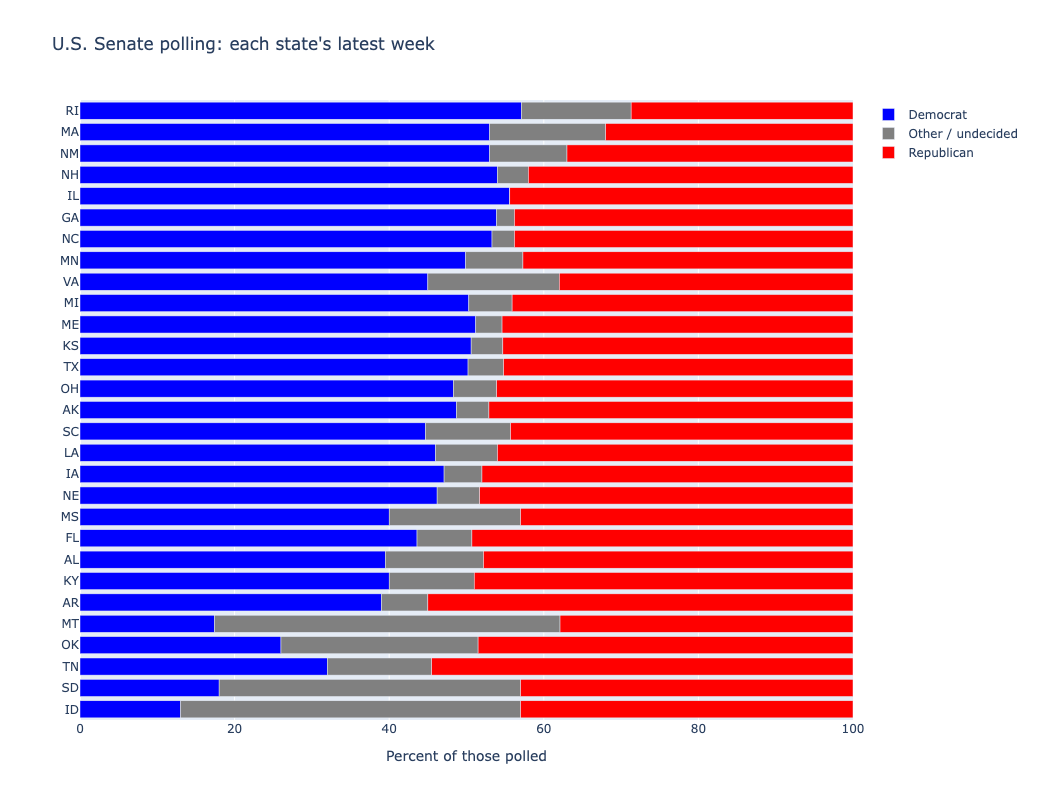

In [6]:
# a dictionary of the names we want in the legend: {old column name: new name}
party_names = {"dem": "Democrat", "other": "Other / undecided", "rep": "Republican"}

# the color of each bar segment, by its new name 
colors = {"Democrat": "blue", "Other / undecided": "grey", "Republican": "red"}

# sort the states from the smallest margin (most Republican) to the largest (most Democratic),
# and rename the columns using the dictionary above
senate_sorted = senate.sort_values("margin").rename(columns=party_names)

fig = px.bar(
    senate_sorted,
    x=["Democrat", "Other / undecided", "Republican"],   # a list of columns: each one becomes a segment, stacked left to right
    y="state",                                           # one bar for each state
    orientation="h",                                     # "h" for horizontal bars
    color_discrete_map=colors,                           # which color goes with which segment
    labels={"value": "Percent", "state": "State"},       # px calls the length of each segment "value" in the hover box
    hover_data={"polls": True, "latest": True},          # also show the number of polls and the latest poll date
    height=800,                                          # tall enough for 29 bars
    title="U.S. Senate polling: each state's latest week",
)

fig.update_layout(
    legend_title_text="",                  # remove the legend's default title
    xaxis_title="Percent of those polled",
    xaxis_range=[0, 100],                  # always show the full 0 to 100 percent
    yaxis_title="",
    yaxis={"dtick": 1},                    # label every bar (otherwise Plotly may label every other one)
)

fig.show()

In [7]:


# open the file and load it, just like the JSON files from Part 9
# (encoding="utf-8" makes sure that accented characters are read correctly)
with open("districts_120th.geojson", "r", encoding="utf-8") as file:
    districts = json.load(file)

# a GeoJSON file is a dictionary with a list of "features", and each feature is one shape
print(len(districts["features"]), "districts")

# every feature also has "properties", the facts about the shape. Here, only an id like "AL-3".
# Plotly will match this id to the id in our table.
print(districts["features"][0]["properties"])



435 districts
{'id': 'AL-3'}


In [8]:


# px.choropleth_map() makes a map where each shape is colored by a number in our table
fig = px.choropleth_map(
    house,                                # the table of data
    geojson=districts,                    # the shapes
    locations="id",                       # the column in our table...
    featureidkey="properties.id",         # ...that matches this property of each shape
    color="margin",                       # the column that decides each shape's color
    color_continuous_scale=color_scale,
    range_color=[-20, 20],                # margins of 20 or more (in either direction) get the strongest color
    hover_name="id",                      # the bold title of the hover box
    # which columns to list in the hover box, and how to format them (":.1f" is one decimal place, False hides one)
    hover_data={"id": False, "dem": ":.1f", "rep": ":.1f", "margin": ":.1f", "polls": True, "latest": True},
    labels=labels,
    map_style="carto-positron",           # the light gray background map
    center={"lat": 38.5, "lon": -96},     # where the map is centered at first (the middle of the U.S.)
    zoom=3,                               # how far in the map starts: a bigger number is closer
    height=650,                           # the height of the figure, in pixels
    title="U.S. House polling: the latest week in each polled district",
)

# update_layout() adjusts what's around the map: the margins (l, r, t, b: left, right, top, bottom) and the legend
fig.update_layout(margin={"l": 0, "r": 0, "t": 50, "b": 0}, coloraxis_colorbar=colorbar)

# show the figure in the notebook
fig.show()



NameError: name 'labels' is not defined

Homework save the met webfiles as html in folder focuing on 20th century creation date
piedec map visualizations that show a map into visualize , chain of provenace vs scope of project 

## Week 10 Homework

I'm interested in the plotly lines on maps in python to trace the path of provenance, to do this would first require some additional steps to parse through the JSON to filter the trends of (person, place, date) divided by a semicolon to create a change of locations to plot. zz
below is the sample documentation from the website

In [ ]:
import plotly.graph_objects as go
import pandas as pd

df_airports = pd.read_csv('https://raw.githubusercontent.com/plotly/datasets/master/2011_february_us_airport_traffic.csv')
df_airports.head()

df_flight_paths = pd.read_csv('https://raw.githubusercontent.com/plotly/datasets/master/2011_february_aa_flight_paths.csv')
df_flight_paths.head()

fig = go.Figure()

fig.add_trace(go.Scattergeo(
    locationmode = 'USA-states',
    lon = df_airports['long'],
    lat = df_airports['lat'],
    hoverinfo = 'text',
    text = df_airports['airport'],
    mode = 'markers',
    marker = dict(
        size = 2,
        color = 'rgb(255, 0, 0)',
        line = dict(
            width = 3,
            color = 'rgba(68, 68, 68, 0)'
        )
    )))

flight_paths = []
for i in range(len(df_flight_paths)):
    fig.add_trace(
        go.Scattergeo(
            locationmode = 'USA-states',
            lon = [df_flight_paths['start_lon'][i], df_flight_paths['end_lon'][i]],
            lat = [df_flight_paths['start_lat'][i], df_flight_paths['end_lat'][i]],
            mode = 'lines',
            line = dict(width = 1,color = 'red'),
            opacity = float(df_flight_paths['cnt'][i]) / float(df_flight_paths['cnt'].max()),
        )
    )

fig.update_layout(
    title_text = 'Feb. 2011 American Airline flight paths<br>(Hover for airport names)',
    showlegend = False,
    geo = dict(
        scope = 'north america',
        projection_type = 'azimuthal equal area',
        showland = True,
        landcolor = 'rgb(243, 243, 243)',
        countrycolor = 'rgb(204, 204, 204)',
    ),
)

fig.show()